# 02 · Calidad de los datos y diagnóstico: ¿dónde se equivoca el MDA?

Este notebook responde tres preguntas antes de modelar:

1. ¿Hay que modelar los 9 nodos por separado o son, en la práctica, la misma serie?
2. ¿Qué tan bueno es ya el MDA como pronóstico del MTR, y cómo son sus errores (picos, sesgos, horas)?
3. Cuando el MDA se equivoca, ¿en qué componente del precio está el error? La respuesta decide en qué tipo de información vale la pena invertir.

Una aclaración de método: las estadísticas descriptivas usan todo el periodo, porque describen los datos y no ajustan nada. Los diagnósticos que sí orientan decisiones de modelado (oráculos por componente) usan solo 2024. El primer semestre de 2025 queda reservado como test final y no se mira hasta el notebook 11.

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, time, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

# Precios de los 9 nodos en formato largo; la parte descriptiva usa todo 2024 y 2025
from pml.data import cargar_largo, matriz
mtr, mda = cargar_largo()
# las dos semanas de diciembre de 2023 sólo sirven como rezagos; aquí se describen desde enero de 2024
INI = pd.Timestamp('2024-01-01')
mtr, mda = mtr[mtr.fecha >= INI], mda[mda.fecha >= INI]

## 1. ¿Son los 9 nodos la misma serie?

El PML de cada nodo es la suma de energía, pérdidas y congestión. Para cada hora se mide el rango entre nodos (máximo − mínimo), en el PML y en cada componente. Si el rango es pequeño frente a lo que se mueve el precio, no vale la pena tener 9 modelos.

In [2]:
# Para cada hora: diferencia entre el nodo más caro y el más barato (rango), en el PML y en cada componente.
# Si el rango es chico frente a lo que se mueve el precio, los 9 nodos son en la práctica una sola serie.
filas = []
for proc, d in [('MTR', mtr), ('MDA', mda)]:
    for c, nom in [('pml', 'PML'), ('pml_ene', 'energía'), ('pml_per', 'pérdidas'), ('pml_cng', 'congestión')]:
        p = d.pivot_table(index=['fecha', 'hora'], columns='nodo', values=c)
        r = (p.max(axis=1) - p.min(axis=1))
        filas.append({'mercado': proc, 'componente': nom, 'rango mediano': r.median(), 'rango p99': r.quantile(.99),
                      'rango máximo': r.max(), 'desv. estándar del nivel': p.mean(axis=1).std()})
display(pd.DataFrame(filas).round(1))

,mercado,componente,rango mediano,rango p99,rango máximo,desv. estándar del nivel
0,MTR,PML,2.5,32.6,90.3,965.3
1,MTR,energía,0.0,0.0,0.0,984.1
2,MTR,pérdidas,2.5,32.6,90.3,54.2
3,MTR,congestión,0.0,0.5,3.7,130.5
4,MDA,PML,3.0,41.2,181.8,1060.4
5,MDA,energía,0.0,0.0,0.0,1069.1
6,MDA,pérdidas,3.0,41.4,181.8,49.4
7,MDA,congestión,0.0,1.3,11.0,180.4


La energía es idéntica en los 9 nodos y la congestión casi. Lo que los separa son las pérdidas: un par de pesos por MWh en una hora típica y unas decenas en los extremos, frente a un precio que se mueve con una desviación estándar de casi mil. Entonces se modela **una serie de zona** (el promedio de los 9) y al final el pronóstico se pasa a cada nodo sumando su diferencia media con la zona. En el notebook 11 se comprueba que el error queda prácticamente igual en todos.

## 2. El MDA como pronóstico del MTR

El MDA del día *d* se publica antes de que deba emitirse el pronóstico, así que es la referencia natural: si un modelo no supera al MDA, en la práctica no sirve. Se comparan ambos mercados en la zona.

In [3]:
# Serie de zona: promedio de los 9 nodos por hora. "spread" = MTR − MDA, el error de usar el MDA como pronóstico.
z = (mtr.groupby(['fecha', 'hora']).pml.mean().rename('mtr').to_frame()
     .join(mda.groupby(['fecha', 'hora']).pml.mean().rename('mda'))).reset_index()
z['spread'] = z.mtr - z.mda
# marca de tiempo horaria (la hora 1 es de 00:00 a 01:00)
z['ts'] = z.fecha + pd.to_timedelta(z.hora - 1, unit='h')
display(z[['mtr', 'mda', 'spread']].describe().round(1))
print(f'correlación MTR–MDA {z.mtr.corr(z.mda):.3f} | MAE de usar el MDA {z.spread.abs().mean():.1f} | '
      f'sesgo medio {z.spread.mean():.1f} | mediana del spread {z.spread.median():.1f}')
print('horas con MDA ≤ 0:', (z.mda <= 0).sum(), '| con MTR ≤ 0:', (z.mtr <= 0).sum())

,mtr,mda,spread
count,13128.0,13128.0,13128.0
mean,813.4,784.4,28.9
std,965.3,1060.4,922.1
min,21.2,-53.4,-23365.0
25%,399.2,387.5,-66.2
50%,540.9,534.4,-1.6
75%,837.4,775.5,101.9
max,12897.0,26121.9,10964.4


correlación MTR–MDA 0.589 | MAE de usar el MDA 330.1 | sesgo medio 28.9 | mediana del spread -1.6
horas con MDA ≤ 0: 33 | con MTR ≤ 0: 0


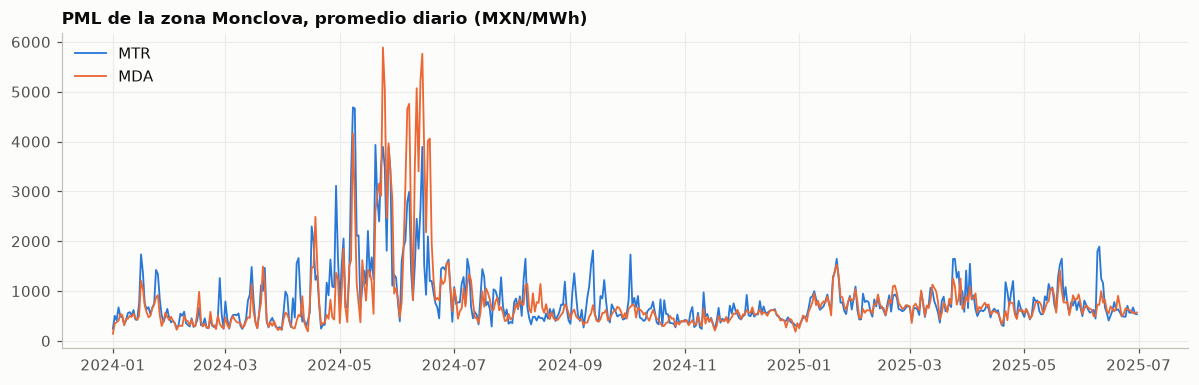

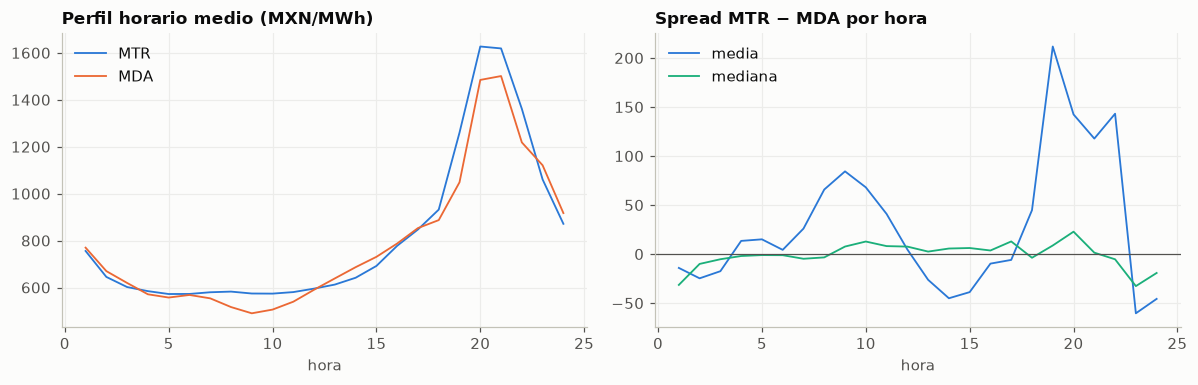

In [4]:
# Dos vistas generales: el promedio diario de los dos mercados y el perfil medio por hora
d = z.groupby('fecha')[['mtr', 'mda']].mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(d.index, d.mtr, color=ps.AZUL, label='MTR'); ax.plot(d.index, d.mda, color=ps.NARANJA, label='MDA')
ax.set_title('PML de la zona Monclova, promedio diario (MXN/MWh)'); ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIG / '02_pml_diario.png'); plt.show()

# izquierda: perfil horario de cada mercado; derecha: el error del MDA por hora (media y mediana)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
h = z.groupby('hora')[['mtr', 'mda']].mean()
axs[0].plot(h.index, h.mtr, color=ps.AZUL, label='MTR'); axs[0].plot(h.index, h.mda, color=ps.NARANJA, label='MDA')
axs[0].set_title('Perfil horario medio (MXN/MWh)'); axs[0].set_xlabel('hora'); axs[0].legend()
s = z.groupby('hora').spread.agg(['mean', 'median'])
axs[1].plot(s.index, s['mean'], color=ps.AZUL, label='media'); axs[1].plot(s.index, s['median'], color=ps.AQUA, label='mediana')
axs[1].axhline(0, color=ps.GRIS, lw=.8); axs[1].set_title('Spread MTR − MDA por hora'); axs[1].set_xlabel('hora'); axs[1].legend()
fig.tight_layout(); fig.savefig(FIG / '02_perfil_horario.png'); plt.show()

En un día normal las dos curvas van juntas: la mediana de la diferencia MTR − MDA es de −1.6 MXN/MWh. La correlación horaria es de apenas 0.59 porque los picos no coinciden ni en hora ni en tamaño. La media es positiva y crece en la rampa de la tarde (19–22 h). Esa diferencia entre media y mediana indica que el error promedio lo dominan unas pocas horas extremas, no un sesgo sistemático. Esto tendrá consecuencias: un estimador que apunte a la media (mínimos cuadrados) va a perseguir esos picos, cuando la métrica del reto (MAE) premia acertar la mediana.

## 3. Picos

El MTR llega a casi 13,000 MXN/MWh y el MDA a 26,000. Se ubica dónde y cuándo ocurren.

mtr     mediana    541 | MAD   261 | horas a más de 5 MAD:  969 | a más de 10 MAD: 290
mda     mediana    534 | MAD   256 | horas a más de 5 MAD:  840 | a más de 10 MAD: 295
spread  mediana     -2 | MAD   118 | horas a más de 5 MAD: 1652 | a más de 10 MAD: 769
horas con MTR > 3000: 325 | MTR > 5000: 150 | MDA > 5000: 162


,ts,mtr,mda,spread
3475,2024-05-24 19:00:00,2757.0,26122.0,-23365.0
4076,2024-06-18 20:00:00,1297.0,15057.0,-13761.0
3958,2024-06-13 22:00:00,2593.0,15696.0,-13104.0
3474,2024-05-24 18:00:00,5938.0,18285.0,-12346.0
2612,2024-04-18 20:00:00,1461.0,13147.0,-11686.0
3981,2024-06-14 21:00:00,3025.0,14008.0,-10983.0
3456,2024-05-24 00:00:00,12791.0,1826.0,10964.0
2611,2024-04-18 19:00:00,1699.0,12318.0,-10619.0


,MTR,MDA,spread,horas_MTR_mayor_3000
mes,,,,
2024-01,666.0,542.0,124.0,7
2024-02,410.0,377.0,33.0,6
2024-03,549.0,467.0,83.0,4
2024-04,993.0,691.0,302.0,44
2024-05,2175.0,1999.0,176.0,111
2024-06,1525.0,2360.0,-835.0,50
2024-07,829.0,734.0,95.0,10
2024-08,628.0,670.0,-42.0,14
2024-09,720.0,509.0,210.0,29


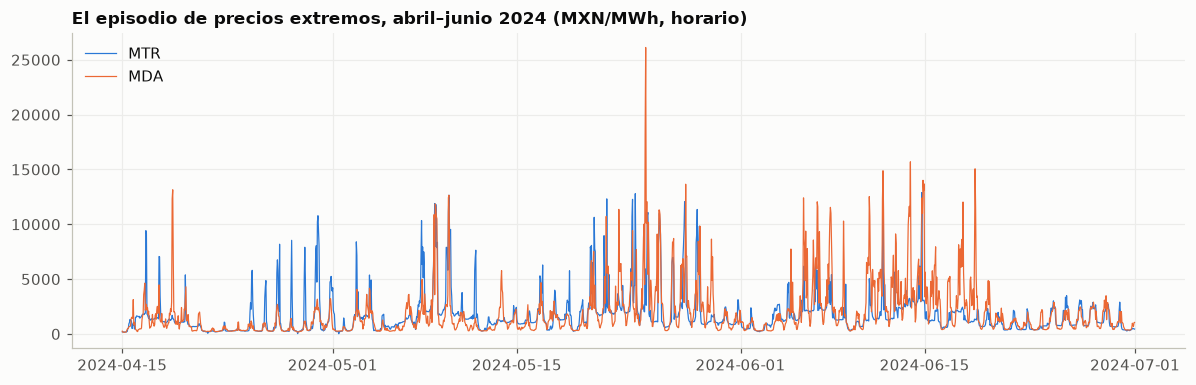

In [5]:
# Qué tan extremos son los picos: cuántas horas se alejan más de 5 y 10 MAD de la mediana (la MAD es la dispersión
# robusta, no la arrastran los extremos), las 8 horas con mayor error del MDA y un resumen mensual
def mad(x): return 1.4826 * np.median(np.abs(x - np.median(x)))
for c in ['mtr', 'mda', 'spread']:
    x = z[c]; m, s = x.median(), mad(x)
    print(f'{c:7s} mediana {m:6.0f} | MAD {s:5.0f} | horas a más de 5 MAD: {(np.abs(x-m)/s>5).sum():4d} | a más de 10 MAD: {(np.abs(x-m)/s>10).sum()}')
print('horas con MTR > 3000:', (z.mtr > 3000).sum(), '| MTR > 5000:', (z.mtr > 5000).sum(), '| MDA > 5000:', (z.mda > 5000).sum())
display(z.assign(abs_sp=z.spread.abs()).nlargest(8, 'abs_sp')[['ts', 'mtr', 'mda', 'spread']].round(0))
dd = z.assign(mes=z.fecha.dt.to_period('M').astype(str)).groupby('mes').agg(
    MTR=('mtr', 'mean'), MDA=('mda', 'mean'), spread=('spread', 'mean'), horas_MTR_mayor_3000=('mtr', lambda x: (x > 3000).sum())).round(0)
display(dd)
# acercamiento al episodio de precios extremos de la primavera de 2024
g = z[z.fecha.between('2024-04-15', '2024-06-30')]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(g.ts, g.mtr, color=ps.AZUL, lw=.8, label='MTR'); ax.plot(g.ts, g.mda, color=ps.NARANJA, lw=.8, label='MDA')
ax.set_title('El episodio de precios extremos, abril–junio 2024 (MXN/MWh, horario)'); ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIG / '02_episodio_picos.png'); plt.show()

Los picos se concentran en la primavera de 2024, el periodo de emergencias del sistema por calor y falta de reserva. Hay un detalle inesperado: los spreads más grandes no son picos del MTR, sino **picos del MDA que el tiempo real no confirmó**. El 24 de mayo de 2024 a las 19 h, el MDA marcó 26,122 y el MTR 2,757. El error va en las dos direcciones. Para el diseño importan tres cosas:

- **Transformación:** hay horas con MDA negativo o cero, así que el logaritmo no sirve. Se usa asinh (arcoseno hiperbólico) con escala robusta, el estándar en la literatura de precios eléctricos: se comporta como lineal cerca de la mediana y como logaritmo en las colas.
- **Entrenamiento:** el episodio extremo cae en los datos de entrenamiento de casi todos los modelos. Conviene recortar el objetivo en entrenamiento para que unas pocas horas no dominen el ajuste.
- **Evaluación:** siempre se reporta el MAE con y sin los días de pico (algún MTR > 3000), porque ningún modelo los anticipa y mueven mucho el promedio.

### ¿Cuántos días tienen pico y cuánto pesan en el error del MDA?

Antes de decidir cuánto esfuerzo poner en los picos conviene medirlos. Un **día con pico** es un día en que el MTR de la zona supera 3,000 MXN/MWh en alguna hora; también se cuentan los umbrales de 2,000 y 5,000 para ver qué tanto depende el conteo de esa elección. Se miden dos cosas: cuántos días son, y qué parte del error total del MDA (la diferencia absoluta entre MTR y MDA) ocurre en ellos. Se separa por semestre porque cada uno cumple un papel distinto en el proyecto: el primero de 2024 sirve para entrenar, el segundo para elegir modelos y el de 2025 es el test.

,días,días con MTR > 2000,días con pico (MTR > 3000),días con MTR > 5000,"error medio del MDA, días normales","error medio del MDA, días con pico",% de los días con pico,% del error del MDA en días con pico,cuántas veces más error en un día con pico
2024 ene–jun (entrenamiento),182.0,82.0,54.0,36.0,296.7,1270.7,29.7,64.4,4.3
2024 jul–dic (desarrollo),184.0,64.0,31.0,10.0,168.3,484.6,16.8,36.8,2.9
2025 ene–jun (test),181.0,39.0,18.0,8.0,140.6,571.1,9.9,31.0,4.1


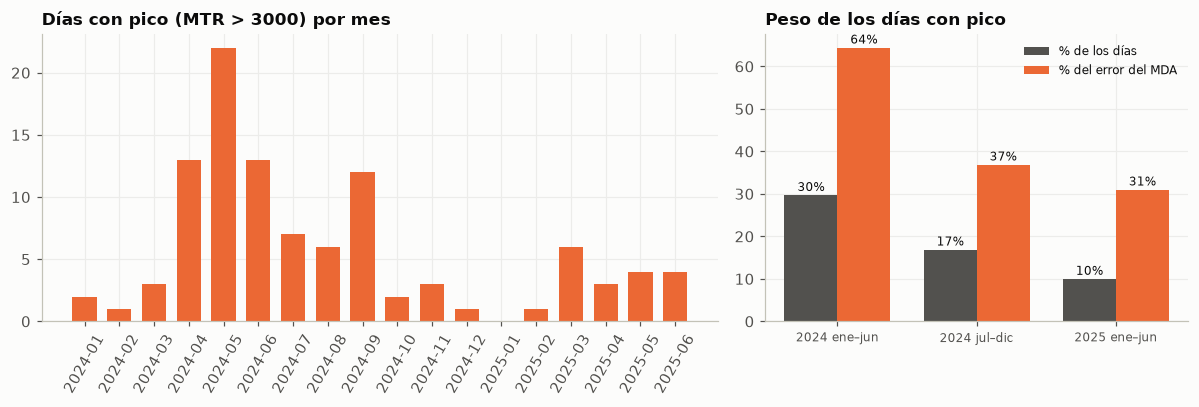

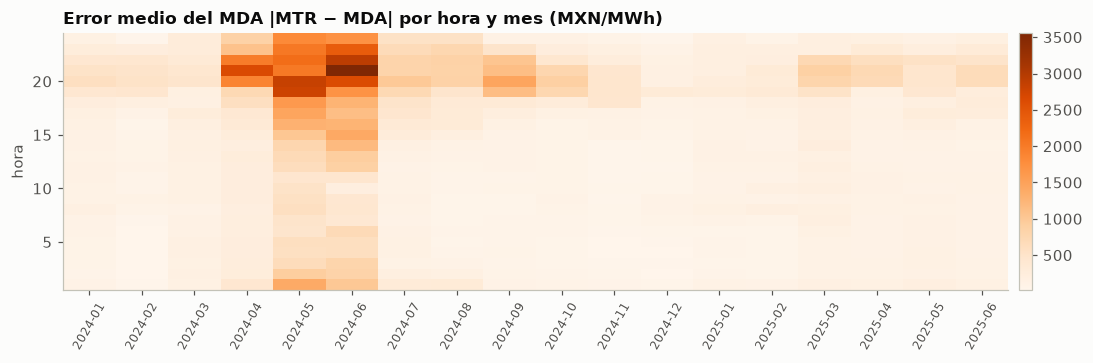

In [6]:
# Días con pico (MTR > 3000 en alguna hora): cuántos hay por semestre y qué parte del error del MDA cargan
zd = z.groupby('fecha').agg(mtr_max=('mtr', 'max'), err=('spread', lambda s: s.abs().mean()))     # un renglón por día
zd['semestre'] = np.select([zd.index < '2024-07-01', zd.index < '2025-01-01'], ['2024 ene–jun (entrenamiento)', '2024 jul–dic (desarrollo)'], '2025 ene–jun (test)')
zd['pico'] = zd.mtr_max > 3000
filas = {}
for sem, g in zd.groupby('semestre'):
    filas[sem] = {'días': len(g), 'días con MTR > 2000': int((g.mtr_max > 2000).sum()), 'días con pico (MTR > 3000)': int(g.pico.sum()),
                  'días con MTR > 5000': int((g.mtr_max > 5000).sum()),
                  'error medio del MDA, días normales': g.err[~g.pico].mean(), 'error medio del MDA, días con pico': g.err[g.pico].mean(),
                  '% de los días con pico': 100 * g.pico.mean(), '% del error del MDA en días con pico': 100 * g.err[g.pico].sum() / g.err.sum()}
TP = pd.DataFrame(filas).T
TP['cuántas veces más error en un día con pico'] = TP['error medio del MDA, días con pico'] / TP['error medio del MDA, días normales']
display(TP.round(1)); TP.round(2).to_csv(REP / '02_dias_con_pico.csv')

# Figura: días con pico por mes y, por semestre, % de días contra % del error
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1.6, 1]})
mes = zd.groupby(zd.index.to_period('M')).pico.sum()
axs[0].bar(mes.index.astype(str), mes.values, color=ps.NARANJA, width=0.7)
axs[0].set_title('Días con pico (MTR > 3000) por mes'); axs[0].tick_params(axis='x', rotation=60)
x = np.arange(len(TP)); w = 0.38
axs[1].bar(x - w / 2, TP['% de los días con pico'], w, color=ps.GRIS, label='% de los días')
axs[1].bar(x + w / 2, TP['% del error del MDA en días con pico'], w, color=ps.NARANJA, label='% del error del MDA')
for i, (a, b) in enumerate(zip(TP['% de los días con pico'], TP['% del error del MDA en días con pico'])):
    axs[1].text(i - w / 2, a + 1, f'{a:.0f}%', ha='center', fontsize=8); axs[1].text(i + w / 2, b + 1, f'{b:.0f}%', ha='center', fontsize=8)
axs[1].set_xticks(x, [s.split(' (')[0] for s in TP.index], fontsize=8); axs[1].legend(fontsize=8, loc='upper right')
axs[1].set_title('Peso de los días con pico')
fig.tight_layout(); fig.savefig(FIG / '02_dias_con_pico.png'); plt.show()

# Mapa de calor del error del MDA por hora del día (filas) y mes (columnas)
fig, ax = plt.subplots(figsize=(11, 3.4))
H = z.assign(mes=z.fecha.dt.to_period('M').astype(str), abs_sp=z.spread.abs()).pivot_table(index='hora', columns='mes', values='abs_sp')
im = ax.imshow(H.values, aspect='auto', cmap='Oranges', origin='lower', extent=[-0.5, H.shape[1] - 0.5, 0.5, 24.5])
ax.set_xticks(range(H.shape[1]), H.columns, rotation=60, fontsize=8); ax.set_ylabel('hora'); ax.grid(False)
ax.set_title('Error medio del MDA |MTR − MDA| por hora y mes (MXN/MWh)'); fig.colorbar(im, ax=ax, pad=0.01)
fig.tight_layout(); fig.savefig(FIG / '02_error_hora_mes.png'); plt.show()

Se ve lo siguiente:

- **Los días con pico se fueron haciendo menos frecuentes.** Son el 30% de los días en el primer semestre de 2024, el 17% en el segundo y el 10% en el primero de 2025. Mayo de 2024 tuvo 22 días con pico; en 2025 ningún mes pasa de 6.
- **Pesan mucho más de lo que su número sugiere.** En un día con pico, el error medio del MDA es de 3 a 4 veces el de un día normal: 485 contra 168 en desarrollo y 571 contra 141 en el test. Por eso, siendo el 10% al 17% de los días, cargan entre el 31% y el 37% de todo el error del MDA en desarrollo y test (y el 64% en el primer semestre de 2024).
- **El error se concentra en la noche de la primavera y el verano.** El mapa de calor muestra que el error grande está entre las 19 y las 23 h de abril a junio de 2024 y, en menor medida, en septiembre de 2024 y marzo de 2025. El resto del tiempo el error es chico y parejo.

**Qué significa para el proyecto.** Aun en el test, dos terceras partes del error del MDA están en días normales. Un modelo que no pueda anticipar los picos todavía puede ganarle al MDA si mejora esos días normales, y eso es lo que terminan haciendo los mejores modelos (notebooks 06 a 11). Al mismo tiempo, el tercio del error que está en los días con pico es el techo de lo que no podrá corregirse si los picos resultan imprevisibles (notebooks 09 y 10).

## 4. ¿Cuánta memoria hay con el rezago real?

Al emitir el pronóstico del día *d* (mediodía de *d−1*), el último MTR publicado es el de *d−8*. Se mide cuánto se parece el MTR a sí mismo con rezagos de días, en la misma hora.

In [7]:
# Memoria del MTR: correlación de cada hora consigo misma 1, 2, …, 21 días antes. Al pronosticar sólo se conoce el
# MTR hasta d−8, así que lo relevante son los rezagos de 8 días o más
w = z.pivot(index='fecha', columns='hora', values='mtr'); wm = z.pivot(index='fecha', columns='hora', values='mda')
ac = {k: np.nanmean([w[h].autocorr(k) for h in w.columns]) for k in [1, 2, 7, 8, 9, 10, 14, 21]}
print('autocorrelación del MTR (misma hora) por rezago en días:', {k: round(v, 2) for k, v in ac.items()})
# y el error de "repetir el MTR de hace 8 o 14 días" contra el de usar el MDA
mae_ = lambda a: float(np.abs(a).stack().mean())
idx = w.index[14:]
print('MAE en la misma muestra:', {k: round(mae_((w - f).loc[idx]), 1) for k, f in
      {'MTR de d−8': w.shift(8), 'MTR de d−14': w.shift(14), 'MDA de d': wm}.items()})

autocorrelación del MTR (misma hora) por rezago en días: {1: np.float64(0.6), 2: np.float64(0.41), 7: np.float64(0.37), 8: np.float64(0.31), 9: np.float64(0.27), 10: np.float64(0.28), 14: np.float64(0.34), 21: np.float64(0.34)}
MAE en la misma muestra: {'MTR de d−8': 490.6, 'MTR de d−14': 495.9, 'MDA de d': 336.1}


La memoria disponible es corta. La autocorrelación pasa de 0.6 con un día de rezago (que no se tiene) a cerca de 0.3 con ocho. Repetir el MTR de hace 8 o 14 días se equivoca casi 50% más que el MDA, así que la historia del MTR por sí sola difícilmente le gana al MDA. Se pone a prueba en el notebook 05, porque es justo la pregunta de si el modelo debe aprender más del MTR y menos del MDA.

## 5. ¿En qué componente se equivoca el MDA?

Si se sustituye solo un componente del MDA por su valor real del MTR (un "oráculo"), lo que baja el error es lo máximo que se podría ganar acertando ese componente. No es un modelo, porque usa el futuro a propósito; es una medición del techo. Se usa solo 2024.

In [8]:
# Oráculos por componente: sustituimos UNA componente del MDA por su valor real del MTR. Lo que baja el error es el máximo
# que se podría ganar acertando esa componente. Usa el futuro a propósito: es una medición, no un modelo. Sólo 2024.
DEV = ('2024-07-01', '2024-12-31'); H1 = ('2024-01-15', '2024-06-30')
mtr_c, mda_c = cargar_largo()
def oraculo(a, b):
    E = {p: matriz(mtr_c, p).loc[a:b] for p in ['pml_ene', 'pml_cng', 'pml_per', 'pml']}
    D = {p: matriz(mda_c, p).loc[a:b] for p in ['pml_ene', 'pml_cng', 'pml_per', 'pml']}
    y = E['pml'].values
    f = lambda e, c, p: np.abs(y - (e + c + p).values).mean()
    return {'MDA tal cual': f(D['pml_ene'], D['pml_cng'], D['pml_per']),
            'acertando la energía': f(E['pml_ene'], D['pml_cng'], D['pml_per']),
            'acertando la congestión': f(D['pml_ene'], E['pml_cng'], D['pml_per']),
            'acertando las pérdidas': f(D['pml_ene'], D['pml_cng'], E['pml_per']),
            'acertando energía y congestión': f(E['pml_ene'], E['pml_cng'], D['pml_per'])}
T0 = pd.DataFrame({'2024 ene–jun': oraculo(*H1), '2024 jul–dic': oraculo(*DEV)})
display(T0.round(1)); display((100 * (1 - T0 / T0.loc['MDA tal cual'])).round(0).add_suffix(' (% del error que se elimina)'))

,2024 ene–jun,2024 jul–dic
MDA tal cual,626.1,221.6
acertando la energía,140.9,58.1
acertando la congestión,623.1,227.0
acertando las pérdidas,642.5,228.0
acertando energía y congestión,37.0,14.9


,2024 ene–jun (% del error que se elimina),2024 jul–dic (% del error que se elimina)
MDA tal cual,0.0,0.0
acertando la energía,78.0,74.0
acertando la congestión,0.0,-2.0
acertando las pérdidas,-3.0,-3.0
acertando energía y congestión,94.0,93.0


Casi todo el error está en la **energía**: acertarla eliminaría tres cuartas partes del MAE. Acertar la congestión o las pérdidas de Monclova no ayuda.

¿Qué es la energía? Se comprueba con una semana de datos de nodos de todas las regiones del país.

In [9]:
# ¿La energía es la misma en todo el país? Una semana de datos de 20 nodos de distintas regiones del SIN
from pml.cenace_client import fetch_bloque, a_dataframe
from datetime import date
cat = pd.read_excel(ROOT / 'Catálogo NodosP Sistema Eléctrico Nacional (v2025-06-18).xlsx', sheet_name=0, header=1)
cat.columns = [str(c).strip() for c in cat.columns]
sin = cat[cat.SISTEMA.eq('SIN') & cat['NIVEL DE TENSIÓN (kV)'].isin([115, 230, 400])]
# dos nodos por cada centro de control regional
sel = sin.sort_values('CLAVE').groupby('CENTRO DE CONTROL REGIONAL').head(2)
nodos = sel.CLAVE.str.strip().tolist()[:20]
for p in ['MDA', 'MTR']:
    d = a_dataframe(fetch_bloque(p, date(2024, 7, 1), date(2024, 7, 7), ROOT / 'data/raw/probe', nodos=nodos))
    e = d.pivot_table(index=['fecha', 'hora'], columns='nodo', values='pml_ene')
    c = d.pivot_table(index=['fecha', 'hora'], columns='nodo', values='pml_cng')
    print(f'{p}: {e.shape[1]} nodos de {sel["CENTRO DE CONTROL REGIONAL"].nunique()} regiones | rango de la energía entre nodos: '
          f'{(e.max(axis=1)-e.min(axis=1)).max():.3f} | rango mediano de la congestión: {(c.max(axis=1)-c.min(axis=1)).median():.1f}')

MDA: 14 nodos de 8 regiones | rango de la energía entre nodos: 0.000 | rango mediano de la congestión: 537.5
MTR: 14 nodos de 8 regiones | rango de la energía entre nodos: 0.000 | rango mediano de la congestión: 376.1


La componente de energía es **exactamente la misma en todo el Sistema Interconectado Nacional**: el rango entre 14 nodos de 8 regiones es cero. Lo que hay que pronosticar es un precio nacional, que depende del balance de todo el sistema (demanda nacional, renovables, gas, disponibilidad de plantas), no de lo que pase en Monclova. De esto salen tres decisiones:

- No tiene sentido descomponer los 9 nodos con PCA (son la misma serie). Traer nodos de otras regiones no aporta información nueva sobre la energía, solo su congestión. *Lo que aquí no se anticipaba:* aunque no traigan información nueva, sí traen más ejemplos de cómo se equivoca el MDA, y eso resultó muy útil para los modelos más flexibles (notebook 06).
- El clima de Monclova solo puede aportar en la medida en que se parezca al del resto del país. Las exógenas con más sentido son las de sistema (combustibles, inventarios de gas, demanda de la región vecina); el notebook 03 las revisa y el 07 mide cuánto aportan, que resulta ser poco.
- **La información que más ayudaría es un pronóstico de demanda y renovables del SIN.** Se revisó el SIM de CENACE (`APSIM.aspx` y nombres de reporte plausibles): solo hay reportes ex post, como la *Demanda Real del Sistema*, implementados como formularios ASP.NET y publicados con rezago. No se encontró un pronóstico público de día anterior, así que queda como limitación.

### ¿Y AHMSA?

La carga industrial más grande de la zona es Altos Hornos de México. Su nodo es 06AHM-400. No produce acero desde finales de 2023 y fue declarada en quiebra en noviembre de 2024. Si alguna parte del precio reflejara lo que pasa *dentro* de Monclova, sería la congestión o las pérdidas de ese nodo. Se comparan esas componentes entre los 9 nodos, por trimestre, y se mide cómo se relacionan el error de la energía y el de la parte nodal (congestión + pérdidas).

In [10]:
# AHMSA: ¿cambia la congestión o las pérdidas entre los 9 nodos a lo largo del tiempo? Y ¿cómo se relacionan el error de
# la energía y el de la parte nodal (congestión + pérdidas)?
mtr_q = mtr.assign(trimestre=pd.to_datetime(mtr.fecha).dt.to_period('Q'))
display(pd.concat({'congestión': mtr_q.pivot_table(index='trimestre', columns='nodo', values='pml_cng'),
                   'pérdidas': mtr_q.pivot_table(index='trimestre', columns='nodo', values='pml_per')}, axis=1).round(1))
k = ['nodo', 'fecha', 'hora']
z = mtr.merge(mda, on=k, suffixes=('_r', '_a')).groupby(['fecha', 'hora'])[['pml_r', 'pml_a', 'pml_ene_r', 'pml_ene_a']].mean()
# error del MDA en la energía y en la parte nodal; el error total es su suma
e_ene = z.pml_ene_r - z.pml_ene_a; e_nod = (z.pml_r - z.pml_ene_r) - (z.pml_a - z.pml_ene_a)
print(f'MAE del MDA: energía {e_ene.abs().mean():.1f} | parte nodal {e_nod.abs().mean():.1f} | total {(e_ene + e_nod).abs().mean():.1f} | '
      f'correlación entre los dos errores {e_ene.corr(e_nod):.2f}')

congestión                                                    \
nodo       06AEO-115 06AHM-400 06FRO-115 06GRA-115 06MON-115 06MON-230   
trimestre                                                                
2024Q1         -29.0     -29.0     -29.0     -29.0     -29.0     -29.0   
2024Q2         -13.9     -13.9     -13.9     -13.9     -13.9     -13.9   
2024Q3           5.3       5.3       5.3       5.3       5.3       5.3   
2024Q4         -16.5     -16.5     -16.5     -16.5     -16.5     -16.5   
2025Q1          14.9      14.8      14.9      14.9      14.9      14.8   
2025Q2          19.5      19.5      19.5      19.5      19.5      19.5   

                                         pérdidas                      \
nodo      06RGS-115 06TKS-115 06XOC-115 06AEO-115 06AHM-400 06FRO-115   
trimestre                                                               
2024Q1        -29.0     -29.0     -29.0     -54.6     -56.8     -56.8   
2024Q2        -13.9     -13.9     -13.9     -58.0     -65.1     -67.3   
2024Q3          5.3       5.3       5.3     -15.1     -18.0     -19.3   
2024Q4        -16.5     -16.5     -16.5     -40.1     -41.6     -42.1   
2025Q1         14.9      14.9      14.9     -62.0     -64.0     -65.1   
2025Q2         19.5      19.5      19.5     -46.5     -49.0     -50.4   

                                                                       
nodo      06GRA-115 06MON-115 06MON-230 06RGS-115 06TKS-115 06XOC-115  
trimestre                                                              
2024Q1        -55.0     -56.3     -56.3     -55.8     -56.7     -55.1  
2024Q2        -58.7     -65.0     -65.1     -62.7     -67.0     -59.9  
2024Q3        -15.2     -18.0     -18.0     -17.1     -19.1     -15.4  
2024Q4        -40.1     -41.6     -41.6     -41.0     -42.0     -40.3  
2025Q1        -62.2     -64.1     -64.0     -63.6     -65.0     -62.3  
2025Q2        -46.3     -49.0     -49.0     -48.3     -50.2     -46.5

MAE del MDA: energía 351.2 | parte nodal 97.2 | total 330.1 | correlación entre los dos errores -0.18


La congestión es **idéntica en los 9 nodos**: es la congestión de la región, no la de AHMSA. Las pérdidas difieren apenas unos pesos entre nodos. Cerrar la acerera no dejó una huella propia en el precio de su nodo. Para el pronóstico, Monclova es un solo punto.

El segundo resultado sirve más adelante. El error de la energía y el de la parte nodal tienen **correlación negativa**: cuando la energía sale más cara de lo previsto, la congestión y las pérdidas tienden a compensar. Por eso el error total del MDA es *menor* que el de la energía sola. Pronosticar las componentes por separado obliga a acertar dos cosas que se cancelan, y al probarlo salió peor (ver las ideas descartadas en el README).

**En resumen:** se modela una serie de zona. El MDA es una referencia exigente (la historia del MTR se equivoca casi 50% más), los errores están dominados por picos de un precio nacional, y la métrica premia acertar la mediana. El notebook 03 reúne las exógenas disponibles y el 04 construye la base de evaluación.